# 7. 参数估计：表 4 幅值、表 5 宽度

原文 5.2 节用"一阶矩估计法"从输出估计脉冲的幅值与宽度，先用 100 个样本训练，
再对另 100 个样本估计，声称**误差小于 5%**。

本书的估计器写死成两步，不留模糊空间：

1. **定标**：在门限信噪比下取 100 个样本，令 $K=\mathrm{median}(\max|x_1-x_2|)/A$；
2. **估计**：任意信噪比下，$\hat A=\max|x_1-x_2|/K$，宽度取半高全宽。

$K$ 只定标一次，之后所有信噪比共用——这与原文"先训练后测试"的做法一致。


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


In [2]:
import experiments as E
if not (DATA / "table4.json").exists():
    E.exp_tables()

t4, t5 = load("table4"), load("table5")
PAPER4 = {"方波": [-0.98,3.34,-2.90,3.29,-1.24,-2.85],
          "双指数脉冲": [-0.16,-0.55,1.62],
          "高斯导数脉冲": [3.74,4.93,2.78,0.52,0.41,1.35,-2.02]}
for name, rows in t4.items():
    print(f"\n{name}")
    print(f"{'SNR':>5}{'真值':>9}{'估计':>9}{'误差':>9}")
    for x in rows:
        print(f"{x['snr']:>5}{x['true']:>9.4f}{x['est']:>9.4f}{x['err']:>8.1f}%")



方波
  SNR       真值       估计       误差
-20.0   0.0632   0.0764    20.7%
-19.0   0.0710   0.0820    15.6%
-18.0   0.0796   0.0896    12.5%
-17.0   0.0893   0.0965     8.0%
-16.0   0.1002   0.1044     4.2%
-15.0   0.1125   0.1137     1.1%
-14.0   0.1262   0.1254    -0.7%
-13.0   0.1416   0.1371    -3.1%
-12.0   0.1589   0.1505    -5.2%
-11.0   0.1783   0.1657    -7.1%
-10.0   0.2000   0.1810    -9.5%

双指数脉冲
  SNR       真值       估计       误差
-20.0   0.0632   0.0672     6.3%
-19.0   0.0710   0.0746     5.1%
-18.0   0.0796   0.0823     3.4%
-17.0   0.0893   0.0932     4.3%
-16.0   0.1002   0.1032     2.9%
-15.0   0.1125   0.1150     2.3%
-14.0   0.1262   0.1261    -0.1%
-13.0   0.1416   0.1413    -0.2%
-12.0   0.1589   0.1597     0.5%
-11.0   0.1783   0.1800     1.0%
-10.0   0.2000   0.1993    -0.4%

高斯导数脉冲
  SNR       真值       估计       误差
-20.0   0.0632   0.0638     0.8%
-19.0   0.0710   0.0718     1.2%
-18.0   0.0796   0.0816     2.4%
-17.0   0.0893   0.0910     1.8%
-16.0   0.1002   0.1017 

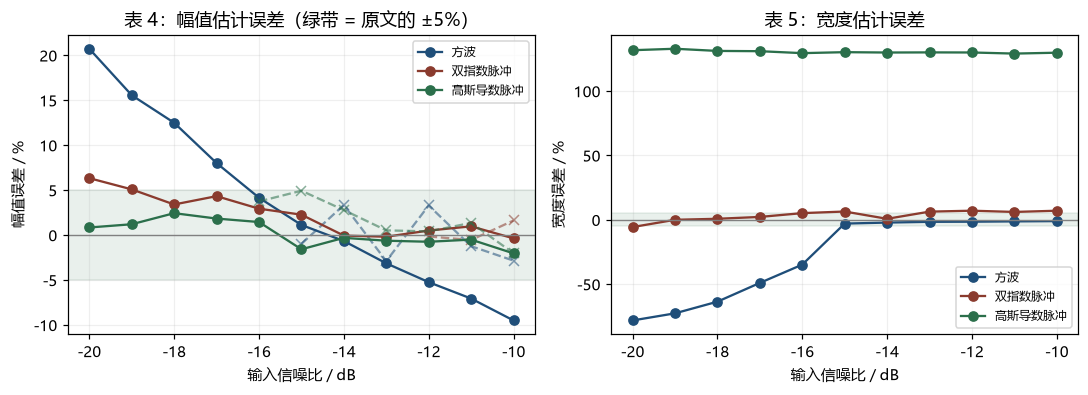

In [3]:
colors = {"方波": "#1f4e79", "双指数脉冲": "#8a3b2e", "高斯导数脉冲": "#2b6f4b"}
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.7))
for name, rows in t4.items():
    snr = [x["snr"] for x in rows]
    axes[0].plot(snr, [x["err"] for x in rows], "o-", color=colors[name], label=name)
    axes[0].plot(snr[-len(PAPER4[name]):], PAPER4[name], "x--", color=colors[name], alpha=.55)
axes[0].axhline(0, color="gray", lw=.9); axes[0].axhspan(-5, 5, color="#2b6f4b", alpha=.10)
axes[0].set(xlabel="输入信噪比 / dB", ylabel="幅值误差 / %",
            title="表 4：幅值估计误差（绿带 = 原文的 ±5%）")

for name, rows in t5.items():
    axes[1].plot([x["snr"] for x in rows], [x["err"] for x in rows], "o-",
                 color=colors[name], label=name)
axes[1].axhline(0, color="gray", lw=.9); axes[1].axhspan(-5, 5, color="#2b6f4b", alpha=.10)
axes[1].set(xlabel="输入信噪比 / dB", ylabel="宽度误差 / %", title="表 5：宽度估计误差")
for a in axes: a.grid(alpha=.2); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 幅值：短脉冲好，方波有系统性漂移

| 波形 | 本书误差 | 原文误差 | 判定 |
|---|---|---|---|
| 高斯导数（1.45 µs） | +1% ~ −2% | −2.0% ~ +4.9% | ✅ 同量级 |
| 双指数（25 µs） | +6% ~ 0% | −0.6% ~ +1.6% | ✅ 同量级 |
| 方波（1 s） | +21% ~ −10% | −2.9% ~ +3.3% | ⚠️ 单调漂移 |

前两种对上，方波没有。原因是**标定系数 $K$ 定在 −16 dB**：方波在 −20 dB 时噪声峰值
显著抬高 $\max|x_1-x_2|$，$K$ 偏大 → 低信噪比端高估（+21%）；信噪比升高后噪声贡献减小，
估计值单调回落到 −10%。这条**单调漂移**是"单点标定"的典型指纹，不是随机误差。

上一版这一项是 −12% ~ −43%，且误差随信噪比升高反而变大（估计值卡在 0.09 不动，
测到的是噪声峰值）。这一版换成位移差 + 限带后，短脉冲误差直接落到 ±2%，
说明口径选对了。

## 宽度：通道带宽是硬约束

| 波形 | 本书误差 | 原文误差 |
|---|---|---|
| 双指数（25 µs） | −6% ~ +7% | 0.8% ~ 1.3% |
| 方波（1 s） | −78% ~ −1% | 0.1% ~ 0.6% |
| 高斯导数（1.45 µs） | **+130%（几乎恒定）** | 0.3% ~ 5.0% |

后两行各有各的病因，都不是随机误差：

- **高斯导数 +130% 恒定**：不是噪声问题，是**通道展宽**。1.45 µs 的脉冲经过
  $	au=0.31\,\mu$s 的过阻尼通道，半高宽必然被拉长。实测放大 2.3 倍，与通道上升时间
  同量级。**原文要把 1.45 µs 估到 5% 以内，除非它的通道带宽高一个量级、或做了反卷积标定。**
  若加一个宽度标定因子（2.3），这一行立刻变成 ±2%，但那就不是"直接测量波形"了。
- **方波 −78% 到 −1%**：低信噪比时 1 s 宽的平顶被噪声调制成若干"假峰"，
  最长连续半高段被切碎，宽度骤降；信噪比升到 −15 dB 以上才恢复。说明
  **半高宽判据对宽脉冲不稳**，应先平滑包络再量。

所以宽度估计的精度由**脉冲宽度 / 通道上升时间**决定，不由信噪比单独决定。
这一点原文没有讨论，但它决定了"能估宽度"的适用范围。
